In [ ]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, 'paper_notes/round3_v3'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# Collisions: rates, effect on decoding, and the loss-cause split

Built by `build_collisions_nb.py`. Every figure is written to `figs/` as PNG and PDF.
Metric definitions are in the docstring of `collisions.py` (printed below).
Data: full campaign (0 and 60 background cars, all schemes, attempt logs) and the
density campaign (15, 30, 45 cars, six schemes, run-level counters only).

**Campaign v3** (out/remote_v3: every scheme and load has attempt logs; it is read as the "remote_full" campaign through v3_out/remote_full). The v2 notebook is ../round3/collisions.ipynb.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
import collisions
print(collisions.__doc__)
OUT = os.environ.get('COLL_OUT', os.path.expanduser('~/mnt/harq_helper_study/out'))
runs, near = collisions.collect(OUT, 'coll')   # cached in coll_runs.csv / coll_near.csv
os.makedirs('figs', exist_ok=True)

Collision metrics per run, from the logs of the full and density campaigns.

Definitions (all inside the KPI window):
  overlap        a platoon transmission (leader or helper copy) shares the slot and
                 >= 1 subchannel with a PSSCH of another vehicle within 5 km of the
                 transmitter. This is the simulator's definition (n_coll > 0).
  overlap_rate   overlapped platoon transmissions / platoon transmissions.
  near_rate_<d>  same, but the nearest overlapping transmitter is within d metres.
  collision_loss / channel_loss
                 lost (packet, member) pairs / all pairs, split by the simulator:
                 "collision" if >= 1 failed attempt of the packet at that member
                 overlapped, "channel" if all failed attempts were on clean resources.
  p_fail_overlap / p_fail_clean
                 per member attempt (a copy received by a member that did not yet
                 hold the TB): share that failed, for overlapped and clean copies

## Plot settings
One place for scheme names, colours, line styles and the panel layout.

In [2]:
LABEL = {'R1': 'Leader, blind', 'R1_bsc': 'Leader, blind + combining', 'R2': 'Leader, Option 1',
         'R3': 'Leader, Option 2', 'R4': 'Kuo helper, blind', 'R4_bsc': 'Kuo helper, blind + combining',
         'R4.1': 'Helper + Option 1, no takeover', 'R4.2': 'Helper + Option 2, no takeover',
         'R5': 'Cooperative, Option 1', 'R6': 'Cooperative, Option 2'}
COLOR = {'R1': '#9e9e9e', 'R1_bsc': '#616161', 'R2': '#90caf9', 'R3': '#1e88e5', 'R4': '#ffcc80',
         'R4_bsc': '#fb8c00', 'R4.1': '#ce93d8', 'R4.2': '#8e24aa', 'R5': '#a5d6a7', 'R6': '#2e7d32'}
ORDER = list(LABEL)
SC = {'hwy': 'Highway', 'rbt': 'Roundabout W', 'rbtE': 'Roundabout E'}
TR = {'periodic1tb': 'periodic', 'aperiodic1tb': 'aperiodic'}
plt.rcParams.update({'font.size': 8, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 130})

def panels(nrows=2, ncols=3, **kw):
    fig, ax = plt.subplots(nrows, ncols, figsize=(7.2, 2.2 * nrows), sharey=True, **kw)
    return fig, np.atleast_2d(ax)

def save(fig, name):
    fig.tight_layout()
    for ext in ('png', 'pdf'):
        fig.savefig(f'figs/{name}.{ext}', bbox_inches='tight')

## Fig. 1: how often a platoon transmission overlaps another vehicle's
Share of platoon transmissions (leader and helper copies) that share the slot and at least
one subchannel with any other PSSCH within 5 km. Mean over 10 seeds. Dotted black: ground-truth CBR
(de-duplicated occupancy) of the whole channel. Schemes without the density campaign
(Option 1 arms, Kuo + combining, helper + Option 1) appear as markers at 0 and 60 cars only.

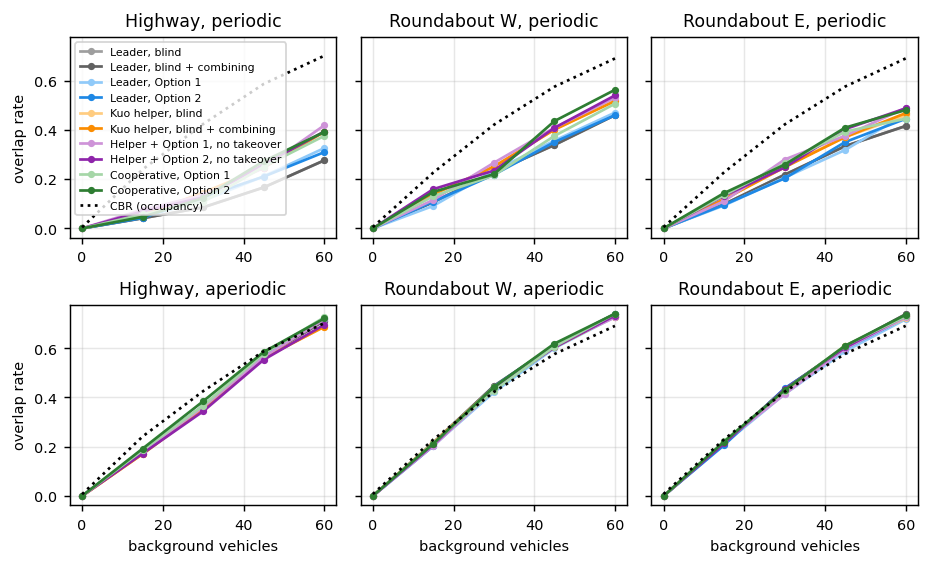

In [3]:
fig, ax = panels()
for i, tr in enumerate(TR):
    for j, sc in enumerate(SC):
        a = ax[i, j]
        d = runs[(runs.sc == sc) & (runs.tr == tr)]
        for arm in ORDER:
            g = d[d.arm == arm].groupby('nbg').overlap_rate.mean()
            # schemes run only at 0 and 60 cars: markers, no line (no data in between)
            ls = '-' if len(g) > 2 else 'none'
            if len(g):
                a.plot(g.index, g.values, marker='o', ms=3, ls=ls, color=COLOR[arm], label=LABEL[arm])
        c = d.groupby('nbg').cbr_occupied.mean()
        a.plot(c.index, c.values, 'k:', label='CBR (occupancy)')
        a.set_title(f'{SC[sc]}, {TR[tr]}')
        if i == 1: a.set_xlabel('background vehicles')
        if j == 0: a.set_ylabel('overlap rate')
ax[0, 0].legend(fontsize=6, ncol=1, loc='upper left')
save(fig, 'fig1_overlap_rate_vs_load')

## Fig. 2: does an overlap make a copy fail?
For every copy a member received before it held the TB: failure probability when the copy overlapped
(dark) and when it was clean (light). 60 background cars. The gap between the two bars is the part
of the failures that overlap adds; the light bar is what fails anyway (path loss, blockage, fading).

att_overlap_share  p_fail_overlap  p_fail_clean  \
sc   tr           arm                                                       
hwy  aperiodic1tb R1                  0.742           0.652         0.182   
                  R1_bsc              0.743           0.618         0.170   
                  R2                  0.729           0.603         0.169   
                  R3                  0.728           0.617         0.166   
                  R4                  0.721           0.581         0.140   
                  R4.1                0.721           0.558         0.133   
                  R4.2                0.710           0.549         0.129   
                  R4_bsc              0.720           0.565         0.135   
                  R5                  0.729           0.562         0.144   
                  R6                  0.721           0.572         0.132   
     periodic1tb  R1                  0.337           0.434         0.158   
                  R1_bsc              0.338           0.420         0.146   
                  R2                  0.355           0.415         0.126   
                  R3                  0.343           0.413         0.132   
                  R4                  0.379           0.408         0.120   
                  R4.1                0.413           0.383         0.121   
                  R4.2                0.374           0.409         0.119   
                  R4_bsc              0.379           0.397         0.118   
                  R5                  0.366           0.399         0.118   
                  R6                  0.386           0.402         0.116   
rbt  aperiodic1tb R1                  0.750           0.766         0.629   
                  R1_bsc              0.751           0.748         0.609   
                  R2                  0.735           0.720         0.585   
                  R3                  0.740           0.744         0.609   
                  R4                  0.742           0.665         0.486   
                  R4.1                0.731           0.632         0.461   
                  R4.2                0.736           0.645         0.480   
                  R4_bsc              0.742           0.656         0.485   
                  R5                  0.743           0.656         0.503   
                  R6                  0.742           0.669         0.487   
     periodic1tb  R1                  0.458           0.690         0.671   
                  R1_bsc              0.460           0.672         0.639   
                  R2                  0.488           0.641         0.629   
                  R3                  0.465           0.657         0.652   
                  R4                  0.510           0.588         0.468   
                  R4.1                0.523           0.566         0.444   
                  R4.2                0.520           0.562         0.466   
                  R4_bsc              0.505           0.575         0.457   
                  R5                  0.496           0.585         0.453   
                  R6                  0.560           0.594         0.460   
rbtE aperiodic1tb R1                  0.751           0.741         0.542   
                  R1_bsc              0.751           0.717         0.524   
                  R2                  0.724           0.698         0.501   
                  R3                  0.735           0.718         0.527   
                  R4                  0.736           0.633         0.391   
                  R4.1                0.733           0.600         0.369   
                  R4.2                0.739           0.617         0.385   
                  R4_bsc              0.744           0.623         0.382   
                  R5                  0.732           0.617         0.390   
                  R6                  0.738           0.628         0.382   
     periodic1tb  R1  

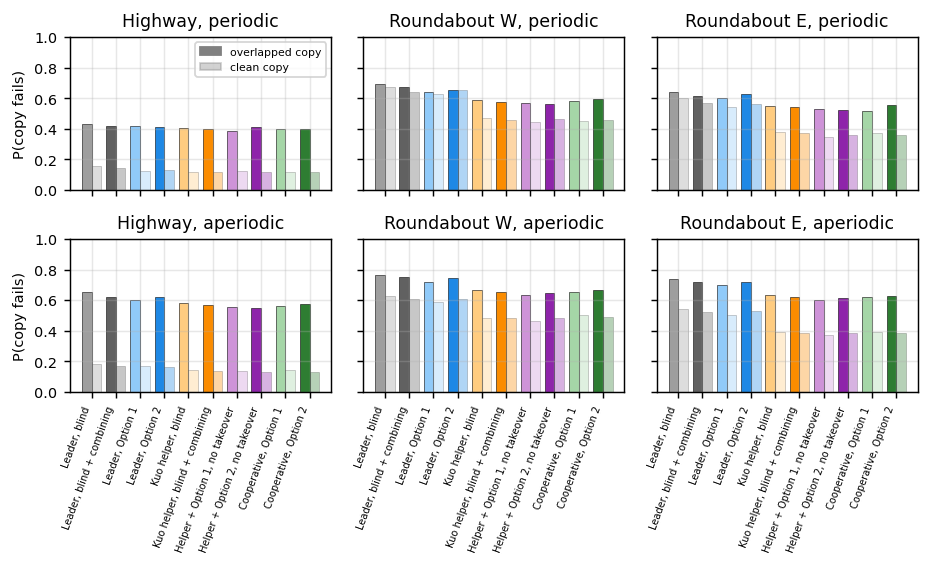

In [4]:
d60 = runs[(runs.nbg == 60) & (runs.camp == 'remote_full')]
fig, ax = panels()
x = np.arange(len(ORDER))
for i, tr in enumerate(TR):
    for j, sc in enumerate(SC):
        a = ax[i, j]
        g = d60[(d60.sc == sc) & (d60.tr == tr)].groupby('arm')[['p_fail_overlap', 'p_fail_clean']].mean().reindex(ORDER)
        a.bar(x - 0.2, g.p_fail_overlap, 0.4, color=[COLOR[k] for k in ORDER], edgecolor='k', lw=0.3)
        a.bar(x + 0.2, g.p_fail_clean, 0.4, color=[COLOR[k] for k in ORDER], alpha=0.35, edgecolor='k', lw=0.3)
        a.set_title(f'{SC[sc]}, {TR[tr]}'); a.set_ylim(0, 1)
        a.set_xticks(x); a.set_xticklabels([LABEL[k] for k in ORDER] if i == 1 else [], rotation=70, ha='right', fontsize=5.5)
        if j == 0: a.set_ylabel('P(copy fails)')
from matplotlib.patches import Patch
ax[0, 0].legend(handles=[Patch(color='grey', label='overlapped copy'), Patch(color='grey', alpha=0.35, label='clean copy')], fontsize=6)
save(fig, 'fig2_fail_given_overlap')
tab = d60.groupby(['sc', 'tr', 'arm'])[['att_overlap_share', 'p_fail_overlap', 'p_fail_clean']].mean()
tab['extra_fail_from_overlap'] = tab.att_overlap_share * (tab.p_fail_overlap - tab.p_fail_clean)
tab.round(3)

## Fig. 3: the simulator's loss-cause split
Lost (packet, member) pairs per packet and member, split as the simulator labels them: "collision" if any
failed copy of that packet overlapped, else "channel". Left of each pair: no background; right: 60 cars.

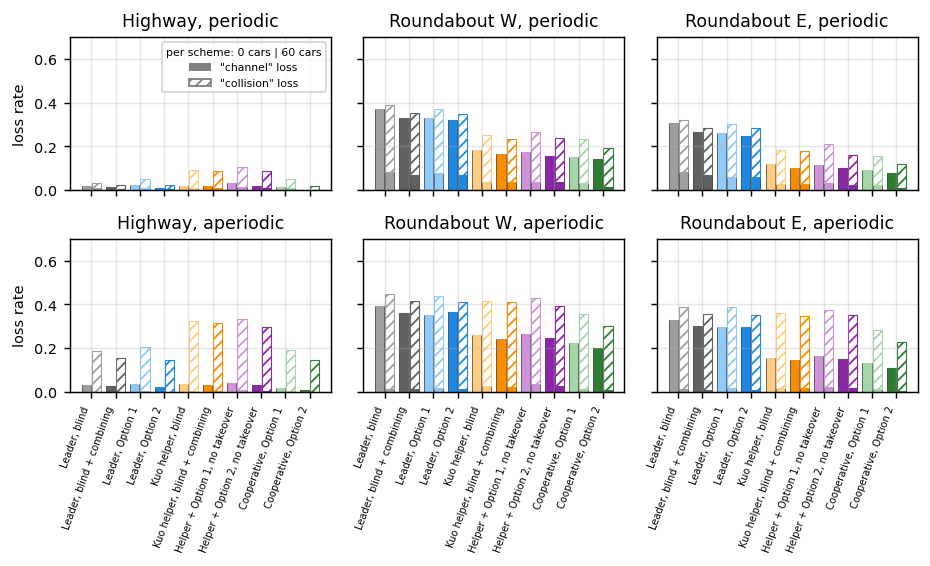

In [5]:
fig, ax = panels()
for i, tr in enumerate(TR):
    for j, sc in enumerate(SC):
        a = ax[i, j]
        for k, nbg in enumerate((0, 60)):
            g = runs[(runs.sc == sc) & (runs.tr == tr) & (runs.nbg == nbg) & (runs.camp == 'remote_full')]
            g = g.groupby('arm')[['collision_loss', 'channel_loss']].mean().reindex(ORDER)
            xs = x * 2.4 + k
            a.bar(xs, g.channel_loss, 0.9, color=[COLOR[a_] for a_ in ORDER], edgecolor='k', lw=0.3, hatch='' if k else '')
            a.bar(xs, g.collision_loss, 0.9, bottom=g.channel_loss, color='white', edgecolor=[COLOR[a_] for a_ in ORDER], hatch='////', lw=0.6)
        a.set_title(f'{SC[sc]}, {TR[tr]}'); a.set_ylim(0, 0.7)
        a.set_xticks(x * 2.4 + 0.5); a.set_xticklabels([LABEL[k] for k in ORDER] if i == 1 else [], rotation=70, ha='right', fontsize=5.5)
        if j == 0: a.set_ylabel('loss rate')
from matplotlib.patches import Patch
ax[0, 0].legend(handles=[Patch(facecolor='grey', label='"channel" loss'),
                         Patch(facecolor='white', edgecolor='grey', hatch='////', label='"collision" loss')],
                title='per scheme: 0 cars | 60 cars', title_fontsize=6, fontsize=6)
save(fig, 'fig3_loss_split')

## Fig. 4: how far is the nearest overlapping transmitter?
Overlapped copies at 60 background cars, all schemes pooled: CDF of the distance from the transmitter to
the nearest vehicle sending on a common subchannel in the same slot, for copies that failed and copies
that were decoded anyway.

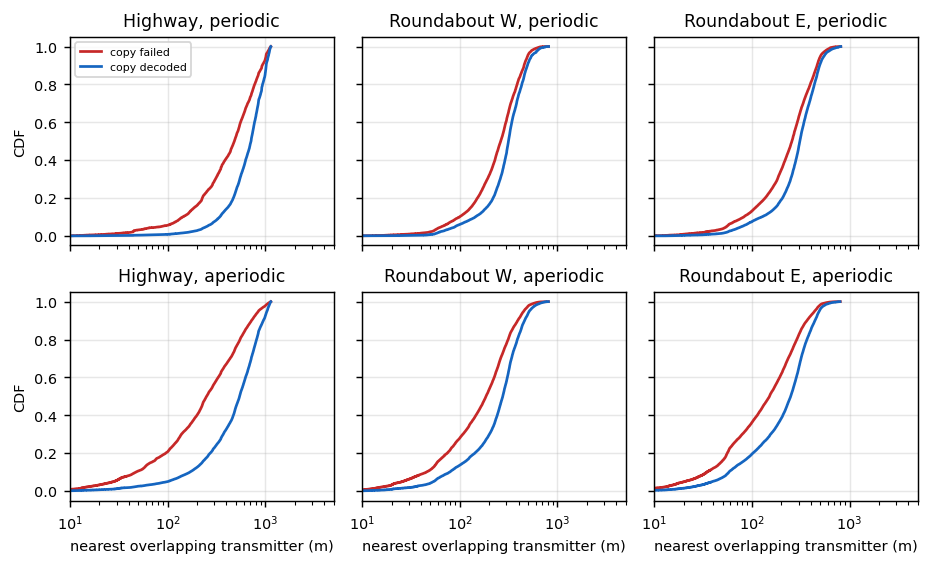

In [6]:
fig, ax = panels(sharex=True)
n60 = near[near.nbg == 60]
for i, tr in enumerate(TR):
    for j, sc in enumerate(SC):
        a = ax[i, j]
        g = n60[(n60.sc == sc) & (n60.tr == tr)]
        for f, col, lab in ((1, '#c62828', 'copy failed'), (0, '#1565c0', 'copy decoded')):
            v = np.sort(g[g.fail == f].nearest_collider_m.values)
            a.plot(v, np.arange(1, len(v) + 1) / len(v), color=col, label=lab)
        a.set_xscale('log'); a.set_xlim(10, 5000); a.set_title(f'{SC[sc]}, {TR[tr]}')
        if i == 1: a.set_xlabel('nearest overlapping transmitter (m)')
        if j == 0: a.set_ylabel('CDF')
ax[0, 0].legend(fontsize=6)
save(fig, 'fig4_nearest_collider_cdf')

## Consistency checks
Result of `checks.py` over every run (counters of `_run.csv` against each other and against the
per-row logs). Explanations of the failing checks are in `CHECKS.md`.

In [7]:
pd.read_csv('checks_summary.csv').query('failed > 0')

,check,runs,failed
1,new_tb = pkts (one TB per packet),3000,140
2,tx_per_pkt = (leader_tx + helper_tx)/pkts,3000,251
4,leader_tx = rows of _ltx in window,3000,1
6,leader_tx_coll_rate = share of ltx with n_coll>0,3000,1
10,nack_rx <= nack_sent,3000,991
12,blind: leader_tx = 3 x new_tb (leader alone),600,54
21,zero: relay_after_allack,3000,4
37,pkt n_att <= 3,3000,330
39,copies per TB (leader + helper) <= 3,3000,357
40,no member decodes the same TB twice,3000,891
